In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Libraries imported")

Libraries imported


In [2]:
from sklearn.datasets import fetch_california_housing

data = fetch_california_housing()
X, y = data.data, data.target

print("Shape of X:", X.shape)
print("Shape of y:", y.shape)
print()
print("Feature names:", data.feature_names)
print()
print("First 5 target values:", y[:5])

Shape of X: (20640, 8)
Shape of y: (20640,)

Feature names: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']

First 5 target values: [4.526 3.585 3.521 3.413 3.422]


In [3]:
df = pd.DataFrame(X, columns=data.feature_names)
df['MedHouseValue'] = y

print("Dataset shape:", df.shape)
print()
print("First 5 rows:")
print(df.head())
print()
print("Statistical summary:")
print(df.describe().round(2))

Dataset shape: (20640, 9)

First 5 rows:
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  MedHouseValue  
0    -122.23          4.526  
1    -122.22          3.585  
2    -122.24          3.521  
3    -122.25          3.413  
4    -122.25          3.422  

Statistical summary:
         MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  \
count  20640.00  20640.00  20640.00   20640.00    20640.00  20640.00   
mean       3.87     28.64      5.43       1.10     1425.48      3.07   
std        1.90     12.59      2.47       0.47     1132.46     10.39   
min        0

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Train size:", X_train.shape)
print("Test size:", X_test.shape)

Train size: (16512, 8)
Test size: (4128, 8)


In [5]:
scaler_X = StandardScaler()
scaler_y = StandardScaler()

X_train_scaled = scaler_X.fit_transform(X_train)
X_test_scaled = scaler_X.transform(X_test)

y_train_scaled = scaler_y.fit_transform(y_train.reshape(-1, 1)).ravel()

print("Scaling done")
print("X_train_scaled mean:", X_train_scaled.mean(axis=0).round(3))
print("X_train_scaled std:", X_train_scaled.std(axis=0).round(3))

Scaling done
X_train_scaled mean: [-0. -0.  0. -0. -0. -0.  0. -0.]
X_train_scaled std: [1. 1. 1. 1. 1. 1. 1. 1.]


In [6]:
poly = PolynomialFeatures(degree=2)

X_poly_train = poly.fit_transform(X_train)
X_poly_test = poly.transform(X_test)

print("Original features:", X_train.shape[1])
print("Polynomial features:", X_poly_train.shape[1])

Original features: 8
Polynomial features: 45


In [7]:
models = {
    "Linear Regression": LinearRegression(),
    "Polynomial Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
    "SVR": SVR(kernel='rbf')
}

print("Models initialized:")
for name in models:
    print(" -", name)

Models initialized:
 - Linear Regression
 - Polynomial Regression
 - Decision Tree
 - Random Forest
 - SVR


In [8]:
results = {}

for name, model in models.items():
    print(f"Training {name} ...")

    if name == "Polynomial Regression":
        model.fit(X_poly_train, y_train)
        y_pred = model.predict(X_poly_test)

    elif name == "SVR":
        model.fit(X_train_scaled, y_train_scaled)
        y_pred_scaled = model.predict(X_test_scaled)
        y_pred = scaler_y.inverse_transform(y_pred_scaled.reshape(-1, 1)).ravel()

    else:
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

    results[name] = {
        "MAE": mean_absolute_error(y_test, y_pred),
        "MSE": mean_squared_error(y_test, y_pred),
        "R2_Score": r2_score(y_test, y_pred)
    }

print()
print("All models trained and evaluated")

Training Linear Regression ...
Training Polynomial Regression ...
Training Decision Tree ...
Training Random Forest ...
Training SVR ...

All models trained and evaluated


In [9]:
results_df = pd.DataFrame(results).T
results_df = results_df.round(4)

print("Model Comparison Results")
print("=" * 60)
print(results_df)

Model Comparison Results
                          MAE     MSE  R2_Score
Linear Regression      0.5332  0.5559    0.5758
Polynomial Regression  0.5162  0.6045    0.5387
Decision Tree          0.4542  0.4943    0.6228
Random Forest          0.3277  0.2560    0.8046
SVR                    0.3973  0.3542    0.7297


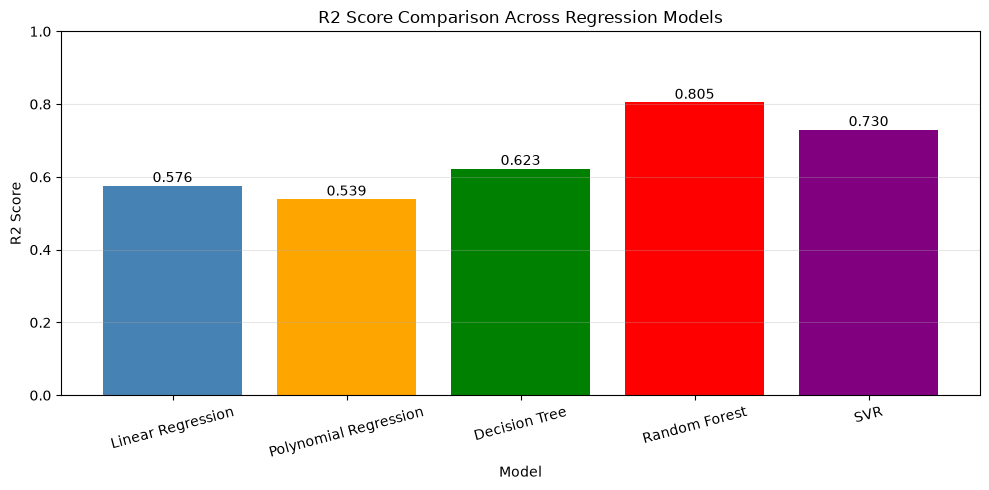

In [10]:
plt.figure(figsize=(10, 5))
colors = ['steelblue', 'orange', 'green', 'red', 'purple']
bars = plt.bar(results_df.index, results_df['R2_Score'], color=colors)

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height + 0.01,
             f"{height:.3f}", ha='center', fontsize=10)

plt.xlabel("Model")
plt.ylabel("R2 Score")
plt.title("R2 Score Comparison Across Regression Models")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.grid(alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

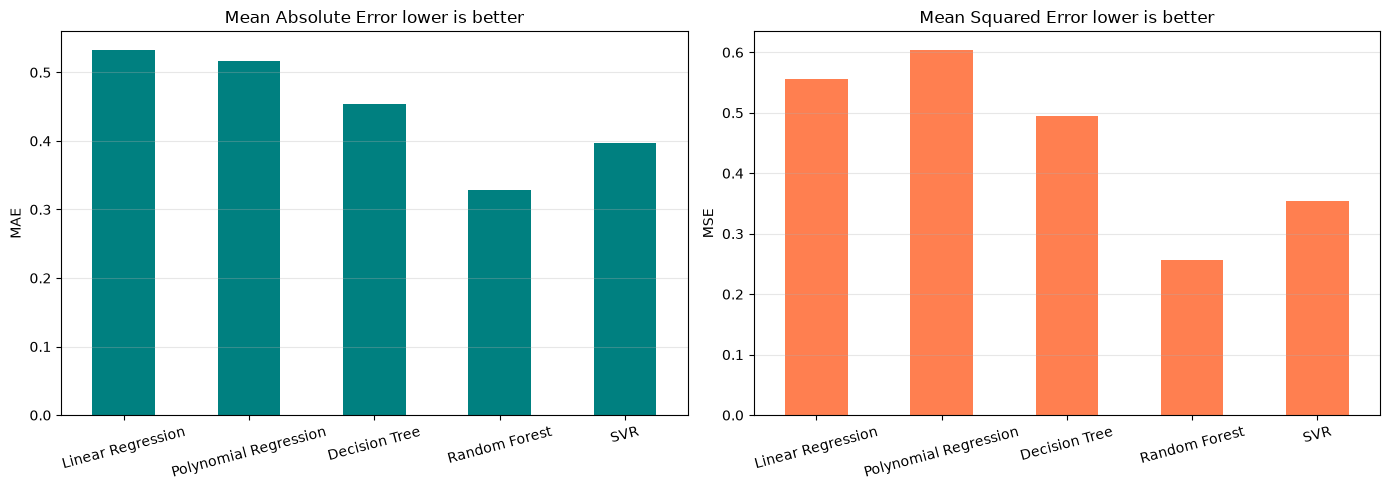

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

results_df['MAE'].plot(kind='bar', ax=axes[0], color='teal')
axes[0].set_title("Mean Absolute Error lower is better")
axes[0].set_ylabel("MAE")
axes[0].tick_params(axis='x', rotation=15)
axes[0].grid(alpha=0.3, axis='y')

results_df['MSE'].plot(kind='bar', ax=axes[1], color='coral')
axes[1].set_title("Mean Squared Error lower is better")
axes[1].set_ylabel("MSE")
axes[1].tick_params(axis='x', rotation=15)
axes[1].grid(alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

In [12]:
best_model_name = results_df['R2_Score'].idxmax()
best_r2 = results_df.loc[best_model_name, 'R2_Score']

print(f"Best model based on R2 Score: {best_model_name}")
print(f"R2 Score: {best_r2:.4f}")

Best model based on R2 Score: Random Forest
R2 Score: 0.8046


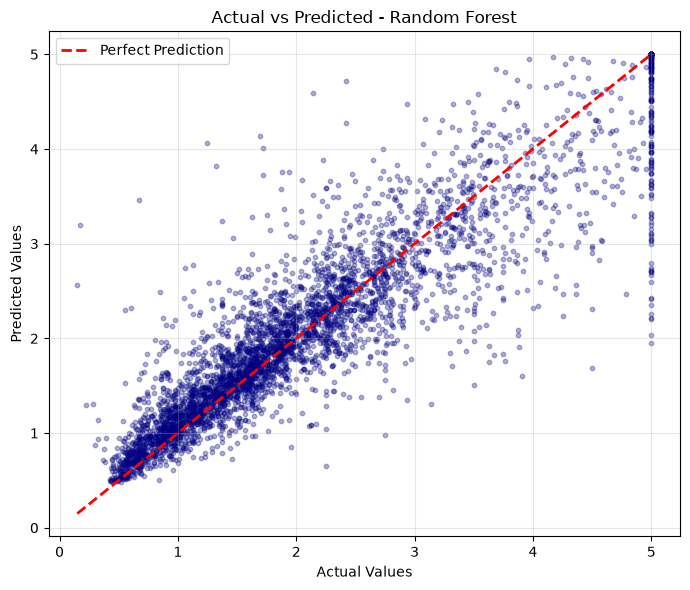

In [13]:
best_model = models[best_model_name]

if best_model_name == "Polynomial Regression":
    y_pred_best = best_model.predict(X_poly_test)
elif best_model_name == "SVR":
    y_pred_best = scaler_y.inverse_transform(
        best_model.predict(X_test_scaled).reshape(-1, 1)
    ).ravel()
else:
    y_pred_best = best_model.predict(X_test)

plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred_best, alpha=0.3, s=10, color='navy')
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()],
         'r--', linewidth=2, label='Perfect Prediction')
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title(f"Actual vs Predicted - {best_model_name}")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [14]:
results_df.to_csv("regression_results.csv")
print("Results saved to regression_results.csv")

Results saved to regression_results.csv
